# Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the Iris Dataset

In [2]:
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset Loaded Successfully!")
print("Features:", iris.feature_names)
print("Target Classes:", iris.target_names)
print("Dataset Shape:", X.shape)

Dataset Loaded Successfully!
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Classes: ['setosa' 'versicolor' 'virginica']
Dataset Shape: (150, 4)


# Display the Dataset

In [3]:
df = pd.DataFrame(X, columns=iris.feature_names)

df["Species"] = iris.target_names[y]

print(df.head(10))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setosa  
8  setosa  
9  setosa 

# Explore the Dataset

In [4]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nClass Distribution:")
print(df["Species"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Statistical Summary:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%  

# Visualize the Data

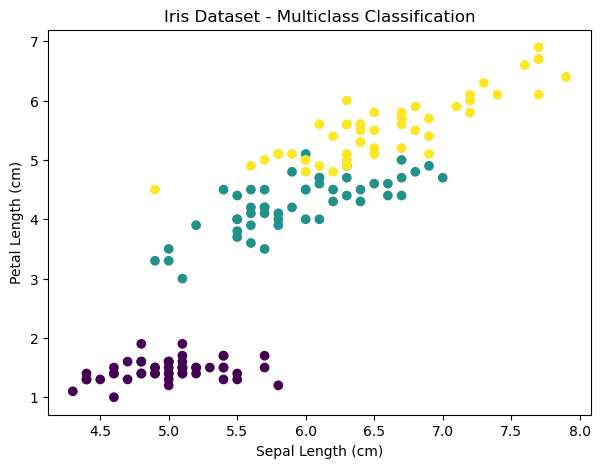

In [5]:
plt.figure(figsize=(7, 5))

plt.scatter(X[:, 0], X[:, 2], c=y)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.title("Iris Dataset - Multiclass Classification")

plt.show()

# Split the Dataset

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (120, 4)
Testing Data: (30, 4)


# Feature Scaling

In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


# Build the Neural Network Model

In [8]:
model = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation="relu",
    solver="adam",
    max_iter=2000,
    random_state=42
)

print("Neural Network Model Created Successfully!")

Neural Network Model Created Successfully!


# Train the Model

In [9]:
model.fit(X_train, y_train)

print("Neural Network Training Completed!")

Neural Network Training Completed!


# Predict the Classes

In [10]:
y_pred = model.predict(X_test)

print("Actual Classes:")
print(iris.target_names[y_test])

print("\nPredicted Classes:")
print(iris.target_names[y_pred])

Actual Classes:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'versicolor' 'versicolor' 'setosa' 'virginica' 'setosa']

Predicted Classes:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'virginica'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


# Calculate Accuracy

In [11]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 96.67 %


# Classification Report

In [12]:
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



# Confusion Matrix

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


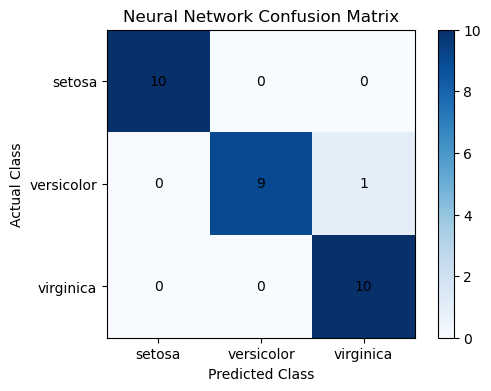

In [13]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(3), iris.target_names)
plt.yticks(range(3), iris.target_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Neural Network Confusion Matrix")

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

# Predict a New Flower

In [14]:
new_flower = np.array([[6.1, 2.8, 4.7, 1.2]])

new_flower = scaler.transform(new_flower)

prediction = model.predict(new_flower)

print("Predicted Flower Species:", iris.target_names[prediction[0]])

Predicted Flower Species: versicolor


# Display Prediction Probabilities

In [15]:
probabilities = model.predict_proba(new_flower)

for i, species in enumerate(iris.target_names):
    print(species, ":", round(probabilities[0][i] * 100, 2), "%")

setosa : 0.25 %
versicolor : 98.37 %
virginica : 1.38 %
